# 04. The assessment pipeline, end to end (runs on CPU, no model needed)
This drives the real pipeline code (validation, quality gate, decision policy, reuse detection, output contract) with a **stub scorer that returns fixed logits**. It demonstrates behaviour and the output contract; the scores are not model output.

In [1]:
import json, os, sys, pathlib
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
ROOT = pathlib.Path(os.getcwd()).resolve().parent if pathlib.Path(os.getcwd()).name == "notebooks" else pathlib.Path(os.getcwd())
sys.path.insert(0, str(ROOT / "src"))
J = lambda n: json.load(open(ROOT / "docs" / "data" / n))
COL = {"blue": "#2f6fb3", "orange": "#d9822b", "grey": "#8a8f98", "green": "#3a9a6e", "red": "#c24d4d"}
import io
from PIL import Image
from fire_assessor.artifact import ModelArtifact
from fire_assessor.authenticity import ReuseIndex
from fire_assessor.decision import Thresholds, decide
from fire_assessor.pipeline import Assessor
from fire_assessor.scorer import ScorerOutput
class StubScorer:   # NOT a model: returns the logits it was given
    def __init__(self, fl, sm): self.fl, self.sm = fl, sm
    def score(self, im):
        rng = np.random.default_rng(int(np.asarray(im.resize((4, 4))).sum())); return ScorerOutput(self.fl, self.sm, rng.normal(size=8), rng.normal(size=8))
def img(seed=0, size=(320, 240)):
    r = np.random.default_rng(seed); return Image.fromarray(r.integers(0, 256, (size[1] // 8, size[0] // 8, 3), dtype=np.uint8)).resize(size, Image.BICUBIC)
def jpg(im, q=90):
    b = io.BytesIO(); im.save(b, "JPEG", quality=q); return b.getvalue()
art = ModelArtifact("fire-assessor-v1.0.0", Thresholds(.5, .5), {"flames": 1., "smoke": 1.}, .05)

## One report through the pipeline

In [2]:
a = Assessor(StubScorer(3., -3.), art, reuse_index=ReuseIndex()); res = a.assess_bytes(jpg(img(1)), "report-001"); print(res.model_dump_json(indent=2))

{
  "assessment_status": "COMPLETED",
  "model_version": "fire-assessor-v1.0.0",
  "scores": {
    "flames_visible": 0.9525741268224334,
    "smoke_visible": 0.04742587317756679
  },
  "derived_label": "ACTIVE_FIRE",
  "decision": "REQUIRES_REVIEW",
  "review_priority": "HIGH",
  "quality_flags": [],
  "ood_flag": false,
  "authenticity": {
    "status": "INCONCLUSIVE",
    "signals": []
  },
  "limitations": [
    "The image alone does not establish location or time.",
    "The assessment does not confirm a wildfire."
  ],
  "error_code": null
}


## What each failure and edge case produces
Every outcome is `REQUIRES_REVIEW` or `UNAVAILABLE`; nothing is auto-rejected.

In [3]:
import pandas as pd
cases = {"normal photo": jpg(img(2)), "too dark": jpg(Image.new("RGB", (300, 300), (4, 4, 4))), "blank grey": jpg(Image.new("RGB", (300, 300), (128, 128, 128))),
         "tiny image": jpg(img(3, (64, 64))), "empty file": b"", "not an image": b"hello", "truncated jpeg": jpg(img(4))[:200]}
out = []
for k, d in cases.items():
    r = Assessor(StubScorer(3., -3.), art).assess_bytes(d, k)
    out.append(dict(case=k, status=r.assessment_status, label=r.derived_label, priority=r.review_priority, quality=",".join(r.quality_flags), error=r.error_code))
pd.DataFrame(out)

assessment unavailable image_id=empty file code=EMPTY_FILE


assessment unavailable image_id=not an image code=UNSUPPORTED_TYPE


assessment unavailable image_id=truncated jpeg code=DECODE_FAILED


,case,status,label,priority,quality,error
0,normal photo,COMPLETED,ACTIVE_FIRE,HIGH,,NaN
1,too dark,COMPLETED,UNCERTAIN,STANDARD,"NEAR_UNIFORM,TOO_DARK",NaN
2,blank grey,COMPLETED,UNCERTAIN,STANDARD,NEAR_UNIFORM,NaN
3,tiny image,COMPLETED,UNCERTAIN,STANDARD,TOO_SMALL,NaN
4,empty file,UNAVAILABLE,NaN,STANDARD,,EMPTY_FILE
5,not an image,UNAVAILABLE,NaN,STANDARD,,UNSUPPORTED_TYPE
6,truncated jpeg,UNAVAILABLE,NaN,STANDARD,,DECODE_FAILED


## Reuse detection: a re-post, a recompressed copy, and a mirrored copy
The second and later uploads of the same photo are flagged `REUSED`; the first upload is not.

In [4]:
a = Assessor(StubScorer(-3., -3.), art, reuse_index=ReuseIndex()); base = img(7)
for nm, d in (("original", jpg(base)), ("same file again", jpg(base)), ("recompressed q40", jpg(base, 40)), ("mirrored", jpg(base.transpose(Image.FLIP_LEFT_RIGHT))), ("different photo", jpg(img(8)))):
    r = a.assess_bytes(d, nm); print(f"{nm:18s} -> {r.authenticity.status:12s} {r.authenticity.signals}")

original           -> INCONCLUSIVE []
same file again    -> REUSED       ['REUSED_MATCHES:original']
recompressed q40   -> REUSED       ['REUSED_MATCHES:original,same file again']
mirrored           -> REUSED       ['REUSED_MATCHES:original,same file again,recompressed q40']
different photo    -> INCONCLUSIVE []


## The decision policy over the score plane
Thresholds 0.5/0.5 and a 0.05 uncertainty margin (illustrative values; the real ones come from calibration). The band around each threshold becomes `UNCERTAIN` and goes to review.

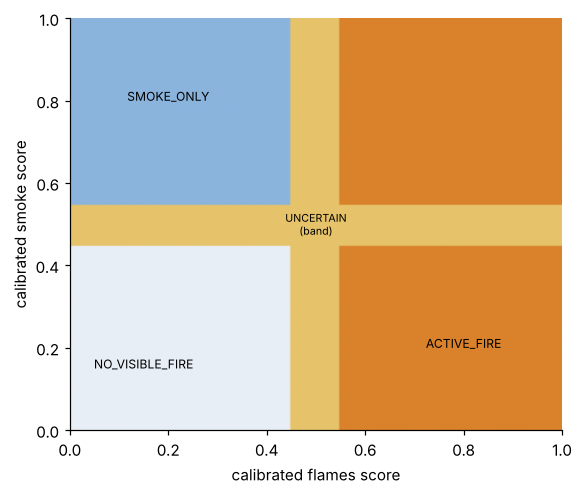

In [5]:
g = np.linspace(0, 1, 201); lab = {"NO_VISIBLE_FIRE": 0, "SMOKE_ONLY": 1, "UNCERTAIN": 2, "ACTIVE_FIRE": 3}
Z = np.array([[lab[decide(pf, ps, Thresholds(.5, .5), [], False).derived_label] for pf in g] for ps in g])
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(5.4, 4.6)); ax.imshow(Z, origin="lower", extent=[0, 1, 0, 1], cmap=ListedColormap(["#e8eef5", "#8bb4dd", "#e6c36a", "#d9822b"]), aspect="auto"); ax.grid(False)
ax.set_xlabel("calibrated flames score"); ax.set_ylabel("calibrated smoke score")
for (x, y_, t) in ((.15, .15, "NO_VISIBLE_FIRE"), (.2, .8, "SMOKE_ONLY"), (.8, .2, "ACTIVE_FIRE")): ax.text(x, y_, t, fontsize=8, ha="center")
ax.text(.5, .5, "UNCERTAIN\n(band)", fontsize=7, ha="center", va="center"); plt.tight_layout(); plt.show()

## Safety property: the model path has no write access to incident status
The service wrapper writes only an assessment field.


In [6]:
import inspect
from fire_assessor import pipeline
print("sink methods:", [n for n, _ in inspect.getmembers(pipeline.AssessmentSink, inspect.isfunction) if not n.startswith("__")])
print("Assessment fields:", list(pipeline.Assessment.model_fields))

sink methods: ['write_assessment']
Assessment fields: ['assessment_status', 'model_version', 'scores', 'derived_label', 'decision', 'review_priority', 'quality_flags', 'ood_flag', 'authenticity', 'limitations', 'error_code']
